# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy import stats

sns.set_style('whitegrid')
sns.set_context('notebook')
os.makedirs('images', exist_ok=True)   # key figures are also saved here for the README

def ci_err(means, sems):
    """95% CI error-bar lengths, with the lower bar cut off at 0 (a share can't be negative)."""
    half = 1.96 * sems
    return np.vstack([np.minimum(half, means), half])

def fmt_p(p):
    """Readable p-value: very small values are shown as p < 0.001."""
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('data/AviationData_Cleaned.csv', low_memory=False)
print(df.shape)
df[['Make', 'Make.Model', 'Total.Passengers', 'Frac.Serious.Fatal', 'Destroyed']].describe(include='all')

(59434, 34)


,Make,Make.Model,Total.Passengers,Frac.Serious.Fatal,Destroyed
count,59434,59434,59434.000000,59434.000000,59434.000000
unique,58,3325,NaN,NaN,NaN
top,Cessna,Cessna 152,NaN,NaN,NaN
freq,25430,2211,NaN,NaN,NaN
mean,NaN,NaN,4.804977,0.271888,0.211327
std,NaN,NaN,23.616973,0.429869,0.408253
min,NaN,NaN,1.000000,0.000000,0.000000
25%,NaN,NaN,1.000000,0.000000,0.000000
50%,NaN,NaN,2.000000,0.000000,0.000000
75%,NaN,NaN,2.000000,0.666667,0.000000


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

**How plane size is assigned**

The number of people on board is used to tell small planes from large passenger planes, with a threshold of **20**. Size is decided **per plane type (`Make.Model`)** rather than per accident, so the same model is never split across both groups:

- Using the *maximum* number on board misclassifies small planes. A few records of small Cessnas and Pipers show 90–140 people, almost certainly mid-air collisions with airliners, where everyone involved was recorded on both aircraft.
- Using the *median* misclassifies some airliners. Many Boeing 747 accidents were cargo flights with only a few crew, so the median for the 747 is just 4.
- The **75th percentile** of people on board avoids both problems: a plane type is **Large** if its 75th percentile is above 20, otherwise **Small**.

In [3]:
q75_passengers = df.groupby('Make.Model')['Total.Passengers'].quantile(0.75)
df['Size'] = np.where(df['Make.Model'].map(q75_passengers) > 20, 'Large', 'Small')

small = df[df['Size'] == 'Small'].copy()
large = df[df['Size'] == 'Large'].copy()

print(df['Size'].value_counts())
df.groupby('Size').agg(accidents=('Size', 'size'),
                       median_on_board=('Total.Passengers', 'median'),
                       mean_frac_serious_fatal=('Frac.Serious.Fatal', 'mean'),
                       destroyed_rate=('Destroyed', 'mean')).round(3)

Size
Small    58066
Large     1368
Name: count, dtype: int64


,accidents,median_on_board,mean_frac_serious_fatal,destroyed_rate
Size,,,,
Large,1368,106.5,0.114,0.124
Small,58066,2.0,0.276,0.213


In [4]:
# Sanity check: the most common plane types in each group
print('Large:', large['Make.Model'].value_counts().head(8).index.tolist())
print('Small:', small['Make.Model'].value_counts().head(8).index.tolist())

Large: ['Boeing 737', 'Bombardier CL6002B19', 'Boeing 747', 'Boeing 737200', 'Boeing 727200', 'Boeing 737300', 'Boeing 777', 'De Havilland DHC6300']
Small: ['Cessna 152', 'Cessna 172', 'Cessna 172N', 'Piper PA28140', 'Cessna 172M', 'Cessna 150', 'Cessna 172P', 'Piper PA18']


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

**Sample-size rule:** to keep comparisons statistically robust, a manufacturer must have at least **50 accidents** in the small group and at least **10** in the large group (large planes have far fewer accidents overall). Error bars on the charts show the **95% confidence interval** of each mean, so wide bars flag estimates based on less data.

In [5]:
def make_summary(data, min_n):
    """Accidents, mean injury fraction (with standard error) and destruction rate per Make."""
    g = data.groupby('Make').agg(accidents=('Make', 'size'),
                                 mean_frac_serious_fatal=('Frac.Serious.Fatal', 'mean'),
                                 sem=('Frac.Serious.Fatal', 'sem'),
                                 destroyed_rate=('Destroyed', 'mean'))
    return g[g['accidents'] >= min_n]

small_makes = make_summary(small, 50)
large_makes = make_summary(large, 10)
print('Qualifying small makes:', len(small_makes), '| qualifying large makes:', len(large_makes))

small_top15 = small_makes.sort_values('mean_frac_serious_fatal').head(15)
large_top15 = large_makes.sort_values('mean_frac_serious_fatal').head(15)
small_top15.round(3)

Qualifying small makes: 53 | qualifying large makes: 10


,accidents,mean_frac_serious_fatal,sem,destroyed_rate
Make,,,,
Waco,138,0.103,0.024,0.087
Grumman-Schweizer,184,0.137,0.025,0.179
Helio,106,0.149,0.033,0.132
Maule,570,0.155,0.014,0.093
Great Lakes,59,0.161,0.047,0.136
Boeing,451,0.164,0.016,0.126
Grumman,1056,0.189,0.012,0.245
Stinson,421,0.198,0.018,0.133
Swearingen,145,0.205,0.032,0.200


In [6]:
large_top15.round(3)

,accidents,mean_frac_serious_fatal,sem,destroyed_rate
Make,,,,
Mcdonnell Douglas,53,0.047,0.023,0.113
Bombardier,76,0.084,0.030,0.079
Canadair,16,0.086,0.063,0.125
Boeing,851,0.105,0.010,0.110
Lockheed,32,0.108,0.052,0.156
Embraer,74,0.114,0.035,0.095
Airbus,132,0.144,0.029,0.159
De Havilland,51,0.161,0.048,0.196
Douglas,57,0.166,0.047,0.158


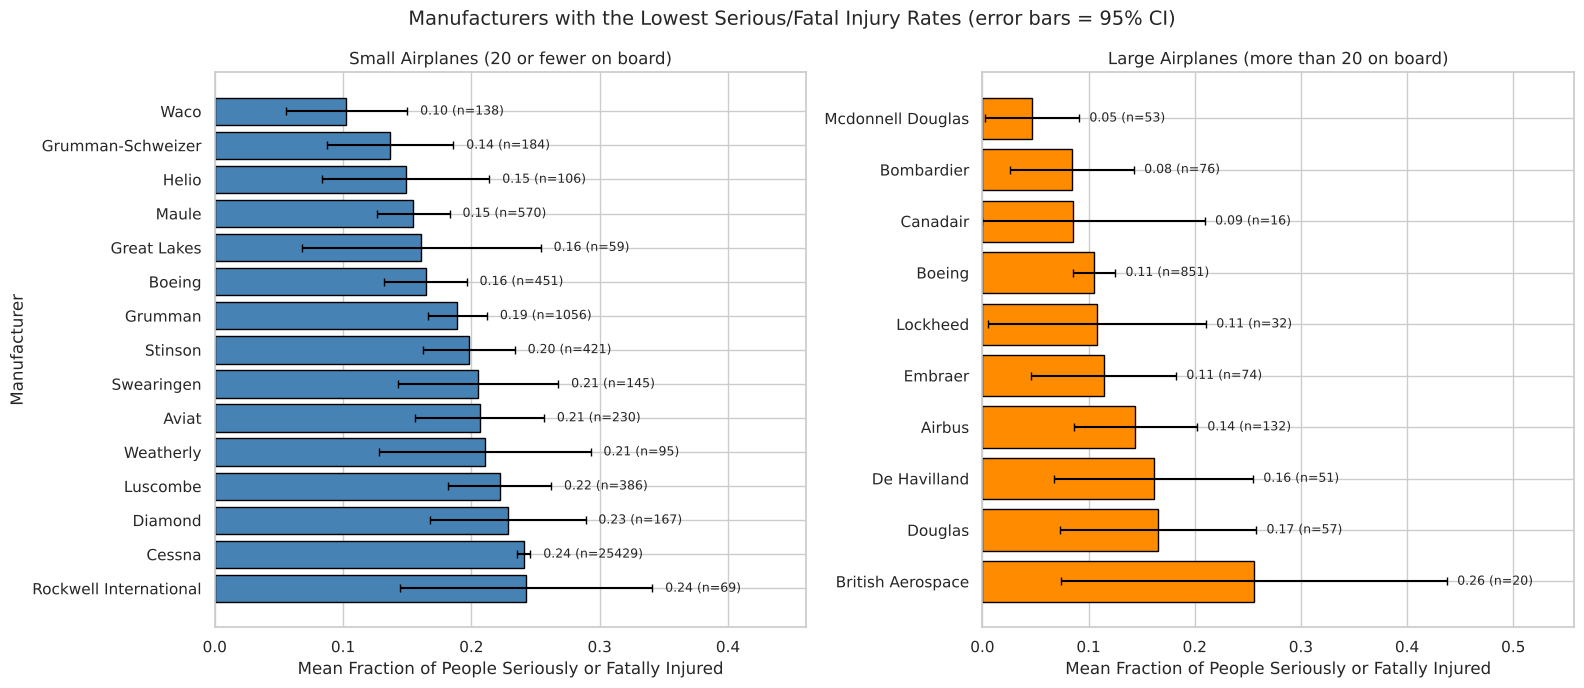

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, data, title, color in [(axes[0], small_top15, 'Small Airplanes (20 or fewer on board)', 'steelblue'),
                               (axes[1], large_top15, 'Large Airplanes (more than 20 on board)', 'darkorange')]:
    means, sems = data['mean_frac_serious_fatal'][::-1], data['sem'][::-1]
    ax.barh(data.index[::-1], means, xerr=ci_err(means, sems), color=color, edgecolor='black', capsize=3)
    for y, (val, se, n) in enumerate(zip(means, sems, data['accidents'][::-1])):
        ax.text(val + 1.96 * se + 0.01, y, f'{val:.2f} (n={n})', va='center', fontsize=9)
    ax.set_title(title)
    ax.set_xlabel('Mean Fraction of People Seriously or Fatally Injured')
    ax.set_xlim(0, (data['mean_frac_serious_fatal'] + 1.96 * data['sem']).max() + 0.12)

axes[0].set_ylabel('Manufacturer')
fig.suptitle('Manufacturers with the Lowest Serious/Fatal Injury Rates (error bars = 95% CI)', fontsize=14)
plt.tight_layout()
plt.savefig('images/makes_lowest_injury.png', dpi=120, bbox_inches='tight')
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

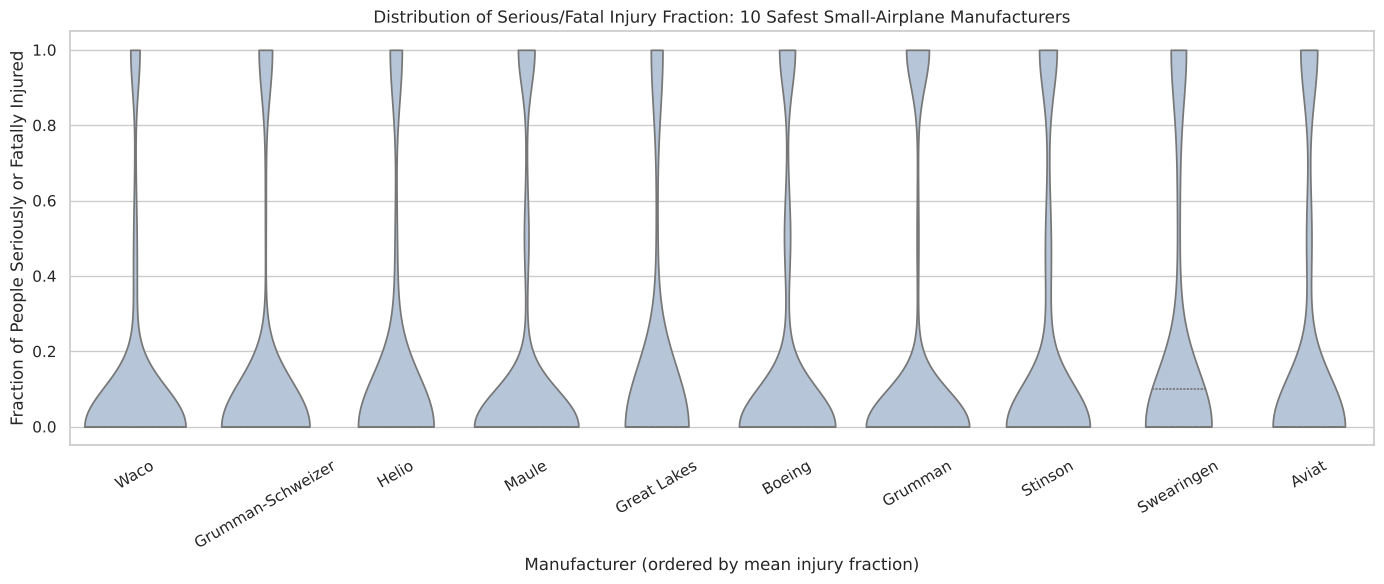

In [8]:
small_top10 = small_makes.sort_values('mean_frac_serious_fatal').head(10).index
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(data=small[small['Make'].isin(small_top10)], x='Make', y='Frac.Serious.Fatal',
               order=small_top10, cut=0, inner='quartile', color='lightsteelblue', ax=ax)
ax.set_title('Distribution of Serious/Fatal Injury Fraction: 10 Safest Small-Airplane Manufacturers')
ax.set_xlabel('Manufacturer (ordered by mean injury fraction)')
ax.set_ylabel('Fraction of People Seriously or Fatally Injured')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
# The distributions are bimodal: most accidents injure nobody seriously (0) or everyone on board (1)
small[small['Make'].isin(small_top10)].groupby('Make')['Frac.Serious.Fatal'].agg(
    median='median', share_no_serious_injury=lambda s: (s == 0).mean(),
    share_all_serious_or_fatal=lambda s: (s == 1).mean()).loc[small_top10].round(3)

,median,share_no_serious_injury,share_all_serious_or_fatal
Make,,,
Waco,0.0,0.870,0.080
Grumman-Schweizer,0.0,0.859,0.130
Helio,0.0,0.821,0.132
Maule,0.0,0.819,0.130
Great Lakes,0.0,0.831,0.153
Boeing,0.0,0.794,0.131
Grumman,0.0,0.797,0.175
Stinson,0.0,0.758,0.159
Swearingen,0.0,0.738,0.172


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

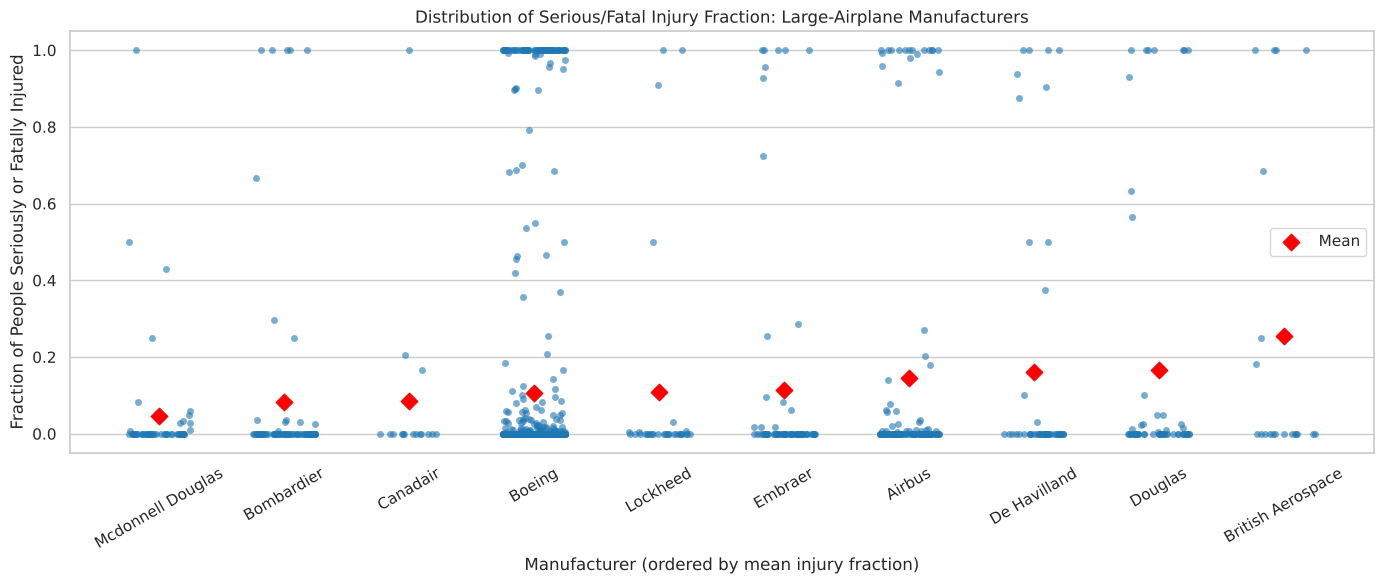

In [10]:
large_top10 = large_makes.sort_values('mean_frac_serious_fatal').head(10).index
fig, ax = plt.subplots(figsize=(14, 6))
sns.stripplot(data=large[large['Make'].isin(large_top10)], x='Make', y='Frac.Serious.Fatal',
              order=large_top10, jitter=0.25, alpha=0.6, ax=ax)
# Mark each manufacturer's mean
means = large[large['Make'].isin(large_top10)].groupby('Make')['Frac.Serious.Fatal'].mean().loc[large_top10]
ax.scatter(range(len(means)), means, color='red', marker='D', s=70, zorder=5, label='Mean')
ax.set_title('Distribution of Serious/Fatal Injury Fraction: Large-Airplane Manufacturers')
ax.set_xlabel('Manufacturer (ordered by mean injury fraction)')
ax.set_ylabel('Fraction of People Seriously or Fatally Injured')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

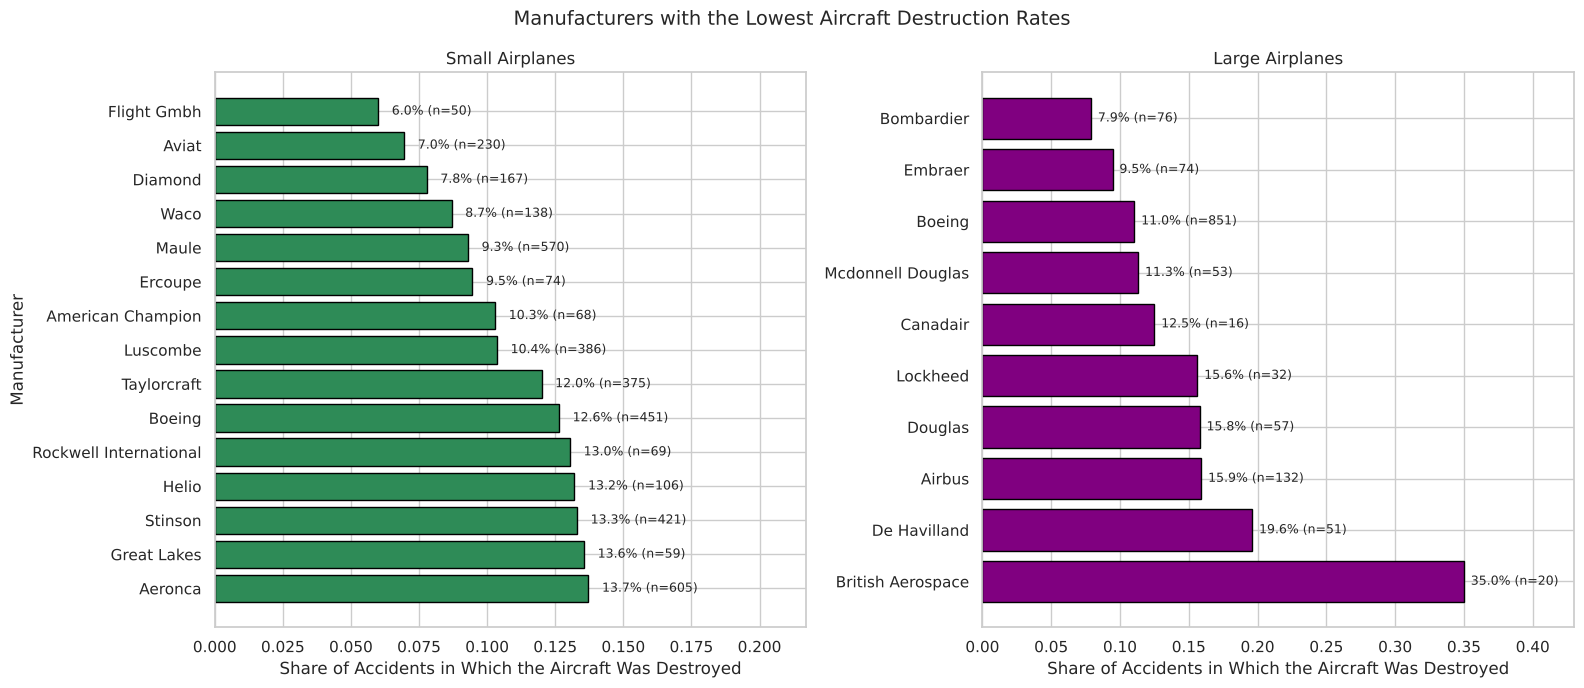

In [11]:
small_destroyed15 = small_makes.sort_values('destroyed_rate').head(15)
large_destroyed15 = large_makes.sort_values('destroyed_rate').head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, data, title, color in [(axes[0], small_destroyed15, 'Small Airplanes', 'seagreen'),
                               (axes[1], large_destroyed15, 'Large Airplanes', 'purple')]:
    ax.barh(data.index[::-1], data['destroyed_rate'][::-1], color=color, edgecolor='black')
    for y, (val, n) in enumerate(zip(data['destroyed_rate'][::-1], data['accidents'][::-1])):
        ax.text(val + 0.005, y, f'{val:.1%} (n={n})', va='center', fontsize=9)
    ax.set_title(title)
    ax.set_xlabel('Share of Accidents in Which the Aircraft Was Destroyed')
    ax.set_xlim(0, data['destroyed_rate'].max() + 0.08)
axes[0].set_ylabel('Manufacturer')
fig.suptitle('Manufacturers with the Lowest Aircraft Destruction Rates', fontsize=14)
plt.tight_layout()
plt.savefig('images/makes_lowest_destroyed.png', dpi=120, bbox_inches='tight')
plt.show()

In [12]:
print('Small airplanes overall destruction rate:', round(small['Destroyed'].mean(), 3))
small_destroyed15[['accidents', 'destroyed_rate', 'mean_frac_serious_fatal']].round(3)

Small airplanes overall destruction rate: 0.213


,accidents,destroyed_rate,mean_frac_serious_fatal
Make,,,
Flight Gmbh,50,0.060,0.370
Aviat,230,0.070,0.207
Diamond,167,0.078,0.228
Waco,138,0.087,0.103
Maule,570,0.093,0.155
Ercoupe,74,0.095,0.340
American Champion,68,0.103,0.294
Luscombe,386,0.104,0.222
Taylorcraft,375,0.120,0.289


In [13]:
print('Large airplanes overall destruction rate:', round(large['Destroyed'].mean(), 3))
large_destroyed15[['accidents', 'destroyed_rate', 'mean_frac_serious_fatal']].round(3)

Large airplanes overall destruction rate: 0.124


,accidents,destroyed_rate,mean_frac_serious_fatal
Make,,,
Bombardier,76,0.079,0.084
Embraer,74,0.095,0.114
Boeing,851,0.110,0.105
Mcdonnell Douglas,53,0.113,0.047
Canadair,16,0.125,0.086
Lockheed,32,0.156,0.108
Douglas,57,0.158,0.166
Airbus,132,0.159,0.144
De Havilland,51,0.196,0.161


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [14]:
# Manufacturers that rank well on BOTH measures: below their group's average injury fraction
# and destruction rate
def strong_on_both(makes, data):
    return makes[(makes['mean_frac_serious_fatal'] < data['Frac.Serious.Fatal'].mean()) &
                 (makes['destroyed_rate'] < data['Destroyed'].mean())].sort_values('mean_frac_serious_fatal')

print('Small-airplane averages: injury fraction', round(small['Frac.Serious.Fatal'].mean(), 3),
      '| destruction rate', round(small['Destroyed'].mean(), 3))
strong_on_both(small_makes, small).round(3).head(12)

Small-airplane averages: injury fraction 0.276 | destruction rate 0.213


,accidents,mean_frac_serious_fatal,sem,destroyed_rate
Make,,,,
Waco,138,0.103,0.024,0.087
Grumman-Schweizer,184,0.137,0.025,0.179
Helio,106,0.149,0.033,0.132
Maule,570,0.155,0.014,0.093
Great Lakes,59,0.161,0.047,0.136
Boeing,451,0.164,0.016,0.126
Stinson,421,0.198,0.018,0.133
Swearingen,145,0.205,0.032,0.200
Aviat,230,0.207,0.026,0.070


In [15]:
print('Large-airplane averages: injury fraction', round(large['Frac.Serious.Fatal'].mean(), 3),
      '| destruction rate', round(large['Destroyed'].mean(), 3))
strong_on_both(large_makes, large).round(3)

Large-airplane averages: injury fraction 0.114 | destruction rate 0.124


,accidents,mean_frac_serious_fatal,sem,destroyed_rate
Make,,,,
Mcdonnell Douglas,53,0.047,0.023,0.113
Bombardier,76,0.084,0.030,0.079
Boeing,851,0.105,0.010,0.110


**Discussion: manufacturers**

*Small airplanes* (average injury fraction 0.276, destruction rate 21.3%)
- **Maule** (570 accidents) is the strongest recommendation. It has a low mean injury fraction (0.155) and one of the lowest destruction rates (9.3%), both backed by a large sample.
- **Aviat** (230 accidents, injury 0.207, destroyed 7.0%) and **Diamond** (167 accidents, injury 0.228, destroyed 7.8%) are also below average on both measures, with the two lowest destruction rates among well-sampled makes.
- **Waco** (0.103) and **Helio** (0.149) have very low injury fractions, and **Boeing** here is the vintage **Stearman biplane** (0.164). These are classic or specialist aircraft with smaller fleets, so they suit a niche insurance product rather than a mainstream one.
- **Cessna** (25,429 accidents) is slightly safer than average (injury 0.241, destroyed 18.9%). Its huge sample makes it the most reliable benchmark.

*Large airplanes* (average injury fraction 0.114, destruction rate 12.4%)
- **Boeing** is the most robust recommendation: 851 accidents with an injury fraction of 0.105 and a destruction rate of 11.0%, both below the large-plane average.
- **Bombardier** (76 accidents, 0.084, 7.9%) and **Embraer** (74 accidents, 0.114, 9.5%) have the lowest destruction rates. They're strong choices for regional jets.
- **McDonnell Douglas** has the lowest injury fraction (0.047), but only 53 accidents, and most of its models are being retired.
- **British Aerospace** (0.256 injury, 35.0% destroyed) performs worst, though with only 20 accidents.

*What the distributions show*
- The injury fraction is **bimodal**: in most accidents either nobody is seriously hurt (0) or everyone on board is (1). The **median** for every one of the 10 safest small makes is **0**: for Maule, 81.9% of accidents caused no serious injury and 13.0% seriously or fatally injured everyone on board. The mean therefore mainly reflects how often an accident becomes catastrophic.
- For large planes the strip plot shows most accidents clustered at **0**. A few catastrophic crashes pull the means up, which is why manufacturers with fewer accidents (Canadair, Lockheed) have wider confidence intervals and should be treated with more caution.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [16]:
def type_summary(data, min_n=10):
    g = data.groupby('Make.Model').agg(accidents=('Make.Model', 'size'),
                                       mean_frac_serious_fatal=('Frac.Serious.Fatal', 'mean'),
                                       sem=('Frac.Serious.Fatal', 'sem'),
                                       destroyed_rate=('Destroyed', 'mean'))
    return g[g['accidents'] >= min_n].sort_values('mean_frac_serious_fatal')

large_types = type_summary(large)
print('Large plane types with at least 10 accidents:', len(large_types))
large_types.round(3)

Large plane types with at least 10 accidents: 31


,accidents,mean_frac_serious_fatal,sem,destroyed_rate
Make.Model,,,,
Boeing 757232,10,0.000,0.000,0.000
Boeing 777,24,0.000,0.000,0.042
Boeing 757222,10,0.000,0.000,0.000
Mcdonnell Douglas MD88,11,0.003,0.003,0.000
Embraer EMB145LR,12,0.007,0.007,0.000
Bombardier CL6002C10,14,0.018,0.018,0.000
Airbus A320232,10,0.026,0.019,0.000
Boeing 727200,25,0.042,0.040,0.040
Boeing 747400,13,0.052,0.052,0.077


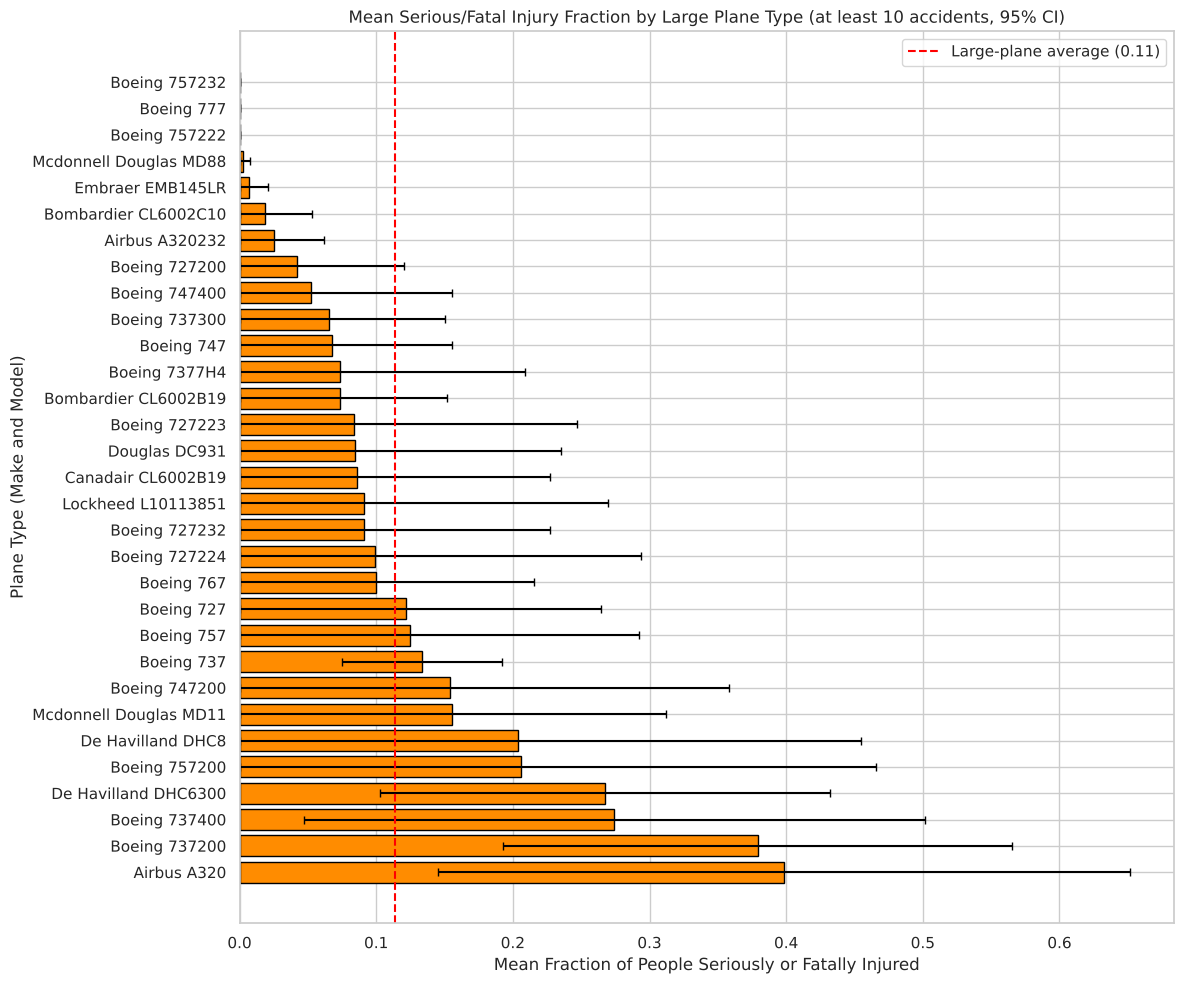

In [17]:
fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(large_types.index[::-1], large_types['mean_frac_serious_fatal'][::-1],
        xerr=ci_err(large_types['mean_frac_serious_fatal'][::-1], large_types['sem'][::-1]),
        color='darkorange', edgecolor='black', capsize=3)
ax.set_xlim(left=0)
ax.axvline(large['Frac.Serious.Fatal'].mean(), color='red', linestyle='--',
           label=f"Large-plane average ({large['Frac.Serious.Fatal'].mean():.2f})")
ax.set_title('Mean Serious/Fatal Injury Fraction by Large Plane Type (at least 10 accidents, 95% CI)')
ax.set_xlabel('Mean Fraction of People Seriously or Fatally Injured')
ax.set_ylabel('Plane Type (Make and Model)')
ax.legend()
plt.tight_layout()
plt.savefig('images/large_plane_types.png', dpi=120, bbox_inches='tight')
plt.show()

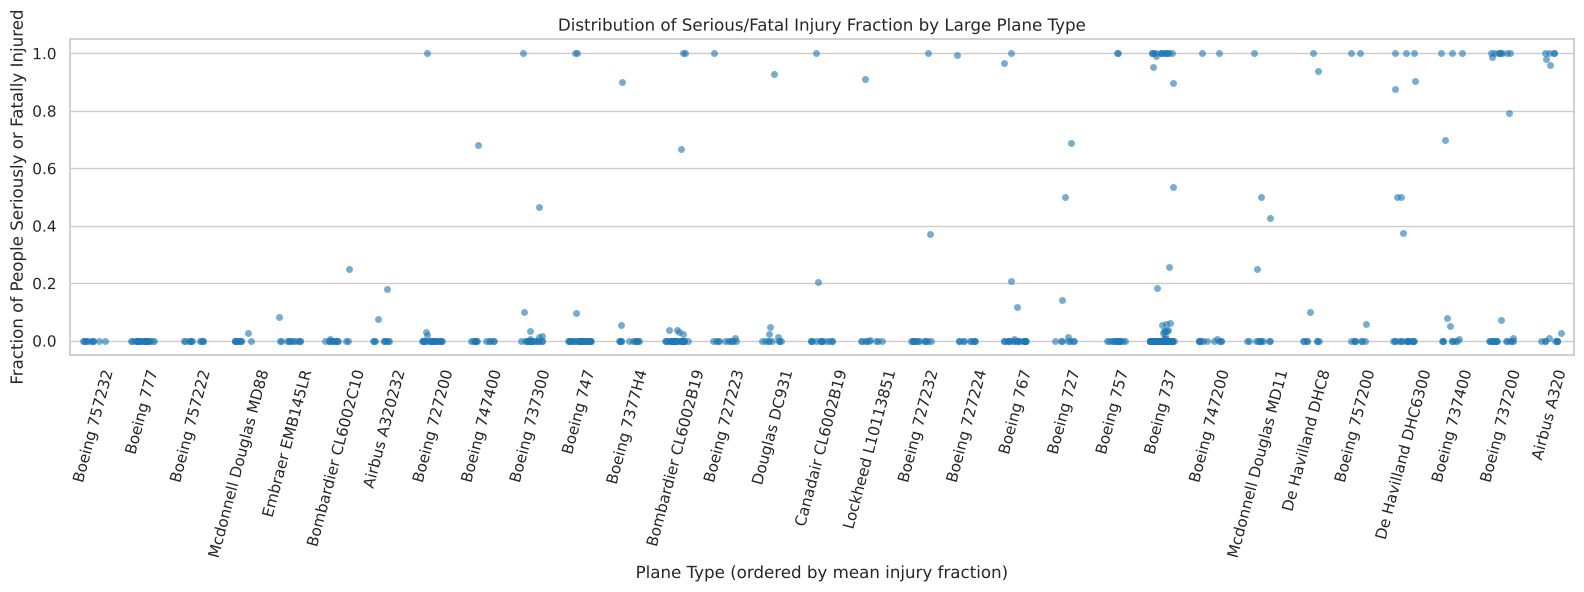

In [18]:
fig, ax = plt.subplots(figsize=(16, 6))
order = large_types.index
sns.stripplot(data=large[large['Make.Model'].isin(order)], x='Make.Model', y='Frac.Serious.Fatal',
              order=order, jitter=0.25, alpha=0.6, ax=ax)
ax.set_title('Distribution of Serious/Fatal Injury Fraction by Large Plane Type')
ax.set_xlabel('Plane Type (ordered by mean injury fraction)')
ax.set_ylabel('Fraction of People Seriously or Fatally Injured')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [19]:
small_types = type_summary(small)
print('Small plane types with at least 10 accidents:', len(small_types))
small_types10 = small_types.head(10)
small_types10.round(3)

Small plane types with at least 10 accidents: 689


,accidents,mean_frac_serious_fatal,sem,destroyed_rate
Make.Model,,,,
Cessna 180C,15,0.000,0.000,0.067
Helio H391B,11,0.000,0.000,0.091
Maule MX7235,24,0.021,0.021,0.042
Maule M4,26,0.038,0.038,0.038
North American AT6G,12,0.042,0.042,0.000
Piper PA18160,33,0.045,0.033,0.030
Cessna L19,11,0.045,0.045,0.091
Diamond DA42,10,0.050,0.050,0.000
Ayres S2R600,20,0.050,0.050,0.200


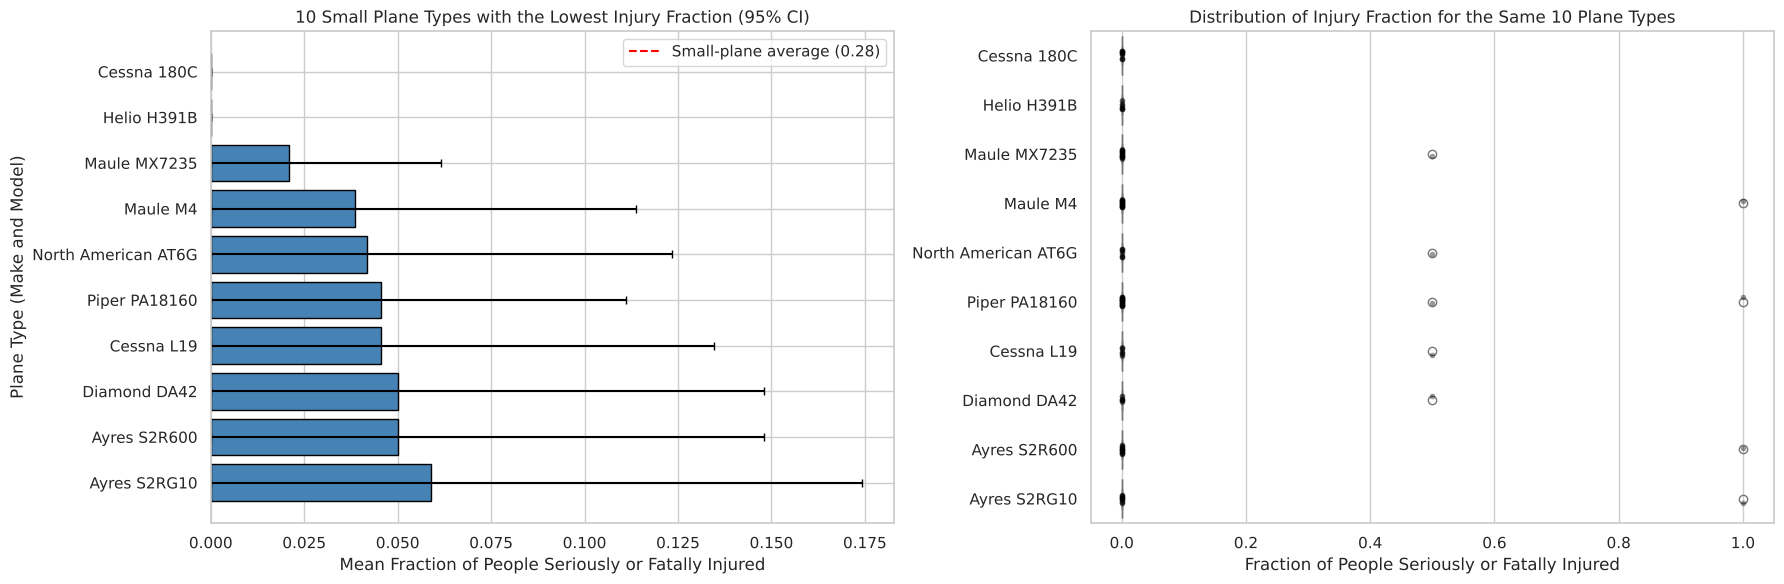

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].barh(small_types10.index[::-1], small_types10['mean_frac_serious_fatal'][::-1],
             xerr=ci_err(small_types10['mean_frac_serious_fatal'][::-1], small_types10['sem'][::-1]),
             color='steelblue', edgecolor='black', capsize=3)
axes[0].set_xlim(left=0)
axes[0].axvline(small['Frac.Serious.Fatal'].mean(), color='red', linestyle='--',
                label=f"Small-plane average ({small['Frac.Serious.Fatal'].mean():.2f})")
axes[0].set_title('10 Small Plane Types with the Lowest Injury Fraction (95% CI)')
axes[0].set_xlabel('Mean Fraction of People Seriously or Fatally Injured')
axes[0].set_ylabel('Plane Type (Make and Model)')
axes[0].legend()

sns.boxplot(data=small[small['Make.Model'].isin(small_types10.index)], x='Frac.Serious.Fatal',
            y='Make.Model', order=small_types10.index, color='lightsteelblue', ax=axes[1])
sns.stripplot(data=small[small['Make.Model'].isin(small_types10.index)], x='Frac.Serious.Fatal',
              y='Make.Model', order=small_types10.index, color='black', alpha=0.4, size=4, ax=axes[1])
axes[1].set_title('Distribution of Injury Fraction for the Same 10 Plane Types')
axes[1].set_xlabel('Fraction of People Seriously or Fatally Injured')
axes[1].set_ylabel('')
plt.tight_layout()
plt.savefig('images/small_plane_types.png', dpi=120, bbox_inches='tight')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [21]:
# Plane types that are low on both measures and have the most data behind them
print('Large types:')
print(large_types[(large_types['destroyed_rate'] <= 0.10)].sort_values('accidents', ascending=False).head(8).round(3))
print('\nSmall types with at least 20 accidents:')
print(small_types[(small_types['accidents'] >= 20)].head(8).round(3))

Large types:
                      accidents  mean_frac_serious_fatal    sem  \
Make.Model                                                        
Bombardier CL6002B19         38                    0.074  0.040   
Boeing 747                   31                    0.068  0.045   
Boeing 727200                25                    0.042  0.040   
Boeing 777                   24                    0.000  0.000   
Boeing 757                   16                    0.125  0.085   
Bombardier CL6002C10         14                    0.018  0.018   
Canadair CL6002B19           14                    0.086  0.072   
Boeing 7377H4                13                    0.073  0.069   

                      destroyed_rate  
Make.Model                            
Bombardier CL6002B19           0.079  
Boeing 747                     0.065  
Boeing 727200                  0.040  
Boeing 777                     0.042  
Boeing 757                     0.062  
Bombardier CL6002C10           0.000  
Cana

**Discussion: specific plane types**

*Large planes* (31 types with at least 10 accidents)
- The **Boeing 777** (24 accidents) had **no** serious or fatal injuries in this data, and was destroyed in only 4.2% of accidents.
- The **Boeing 757** variants (757-232, 757-222), **McDonnell Douglas MD-88**, **Embraer EMB-145LR**, **Bombardier CRJ (CL-600-2C10)** and **Airbus A320-232** all had injury fractions under 0.03 and **no aircraft destroyed**.
- The **Boeing 737-300**, **747** and **CRJ CL-600-2B19** are also below the large-plane average with larger samples (25–38 accidents), which makes their estimates more stable.
- **Note:** "Canadair CL-600-2B19" and "Bombardier CL-600-2B19" are the same aircraft (the CRJ200), recorded under the old and new company name. Canadair became part of Bombardier in 1986.
- **Caution:** many large types have only 10–25 accidents, so their confidence intervals are wide. A rate of 0 from 10 accidents is encouraging but not conclusive. Boeing types are the safest bet because the manufacturer-level result rests on 851 accidents.

*Small planes* (689 types with at least 10 accidents)
- The safest well-sampled small types are the **Maule MX-7-235** (24 accidents, injury 0.021, destroyed 4.2%), the **Maule M-4** (26 accidents, 0.038, 3.8%), the **Piper PA-18-160 Super Cub** (33 accidents, 0.045, 3.0%) and the **Cessna 180A** (61 accidents, 0.066, 3.3%).
- The **Diamond DA42** (10 accidents) recorded an injury fraction of 0.05 and **no aircraft destroyed**. It's a modern twin that matches the strong Diamond result at manufacturer level.
- Several of these are rugged, slow-flying utility or bush planes (Maule, Super Cub, Cessna 180, Helio). Lower landing speeds mean that when accidents happen they tend to be survivable.
- These recommendations line up with the manufacturer results: **Maule** and **Diamond** are recommended at both levels.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

#### Factor 1: Weather Condition
VMC (visual meteorological conditions) means the pilot can see outside; IMC (instrument meteorological conditions) means poor visibility, so the pilot must fly by instruments.

In [22]:
weather = df.dropna(subset=['Weather.Condition']).groupby(['Size', 'Weather.Condition']).agg(
    accidents=('Destroyed', 'size'),
    mean_frac_serious_fatal=('Frac.Serious.Fatal', 'mean'),
    destroyed_rate=('Destroyed', 'mean')).round(3)
weather

accidents  mean_frac_serious_fatal  destroyed_rate
Size  Weather.Condition                                                    
Large IMC                      164                    0.251           0.268
      VMC                      801                    0.056           0.061
Small IMC                     4574                    0.685           0.599
      VMC                    51410                    0.225           0.170

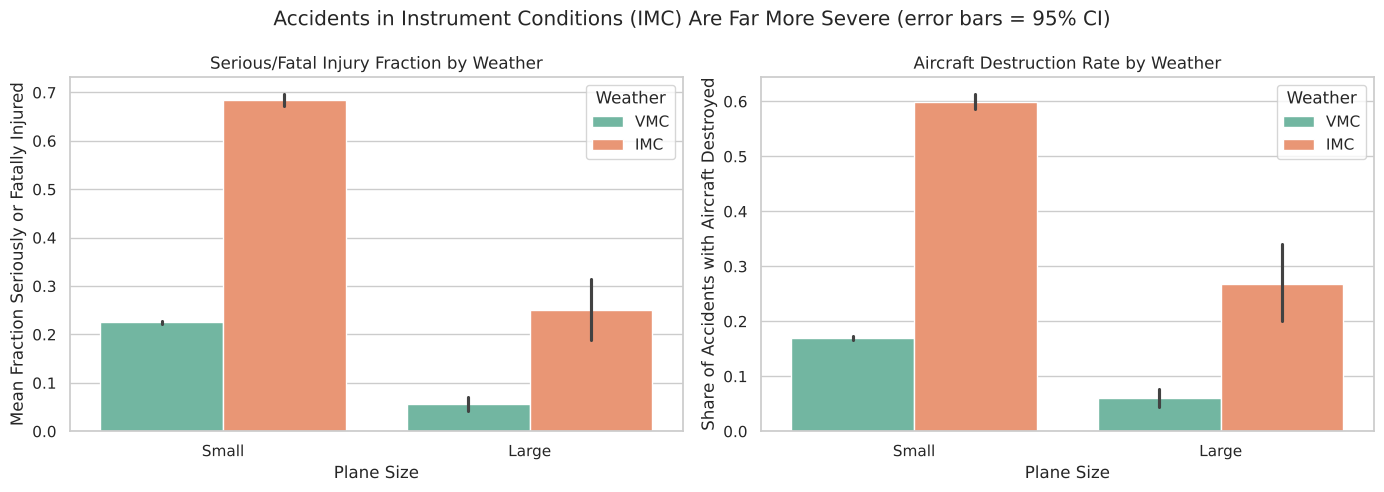

In [23]:
w = df.dropna(subset=['Weather.Condition'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=w, x='Size', y='Frac.Serious.Fatal', hue='Weather.Condition', ax=axes[0], palette='Set2')
axes[0].set_title('Serious/Fatal Injury Fraction by Weather')
axes[0].set_xlabel('Plane Size')
axes[0].set_ylabel('Mean Fraction Seriously or Fatally Injured')
sns.barplot(data=w, x='Size', y='Destroyed', hue='Weather.Condition', ax=axes[1], palette='Set2')
axes[1].set_title('Aircraft Destruction Rate by Weather')
axes[1].set_xlabel('Plane Size')
axes[1].set_ylabel('Share of Accidents with Aircraft Destroyed')
for ax in axes:
    ax.legend(title='Weather')
plt.suptitle('Accidents in Instrument Conditions (IMC) Are Far More Severe (error bars = 95% CI)')
plt.tight_layout()
plt.savefig('images/weather.png', dpi=120, bbox_inches='tight')
plt.show()

In [24]:
# Statistical tests: is the difference between IMC and VMC real?
chi2, p_destroyed, _, _ = stats.chi2_contingency(pd.crosstab(w['Weather.Condition'], w['Destroyed']))
p_injury = stats.mannwhitneyu(w.loc[w['Weather.Condition'] == 'IMC', 'Frac.Serious.Fatal'],
                              w.loc[w['Weather.Condition'] == 'VMC', 'Frac.Serious.Fatal']).pvalue
print('Chi-square test (weather vs destroyed):', fmt_p(p_destroyed))
print('Mann-Whitney test (weather vs injury fraction):', fmt_p(p_injury))

Chi-square test (weather vs destroyed): p < 0.001
Mann-Whitney test (weather vs injury fraction): p < 0.001


**Discussion: weather**
- Weather is the strongest factor in the data. Small planes in **IMC** had a mean injury fraction of **0.685**, against **0.225** in **VMC**, and were destroyed in **59.9%** of accidents against **17.0%**.
- The same pattern holds for **large** planes: injury fraction 0.251 in IMC against 0.056 in VMC, and destruction rate 26.8% against 6.1%.
- Both differences are highly significant (p < 0.001), and with over 4,700 IMC accidents the result is robust.
- **For the client:** flying in poor visibility multiplies the severity of an accident roughly three to four times. Premiums could reflect how often an operator flies in IMC and whether its pilots are instrument-rated.

#### Factor 2: Phase of Flight

In [25]:
phase = df.dropna(subset=['Broad.phase.of.flight']).groupby('Broad.phase.of.flight').agg(
    accidents=('Destroyed', 'size'),
    mean_frac_serious_fatal=('Frac.Serious.Fatal', 'mean'),
    destroyed_rate=('Destroyed', 'mean')).sort_values('mean_frac_serious_fatal')
phase.round(3)

,accidents,mean_frac_serious_fatal,destroyed_rate
Broad.phase.of.flight,,,
Taxi,1480,0.016,0.022
Landing,11890,0.035,0.043
Standing,503,0.080,0.125
Takeoff,8876,0.227,0.219
Go-around,1168,0.299,0.288
Descent,1253,0.340,0.326
Cruise,7098,0.352,0.344
Approach,4559,0.354,0.300
Climb,1430,0.419,0.424


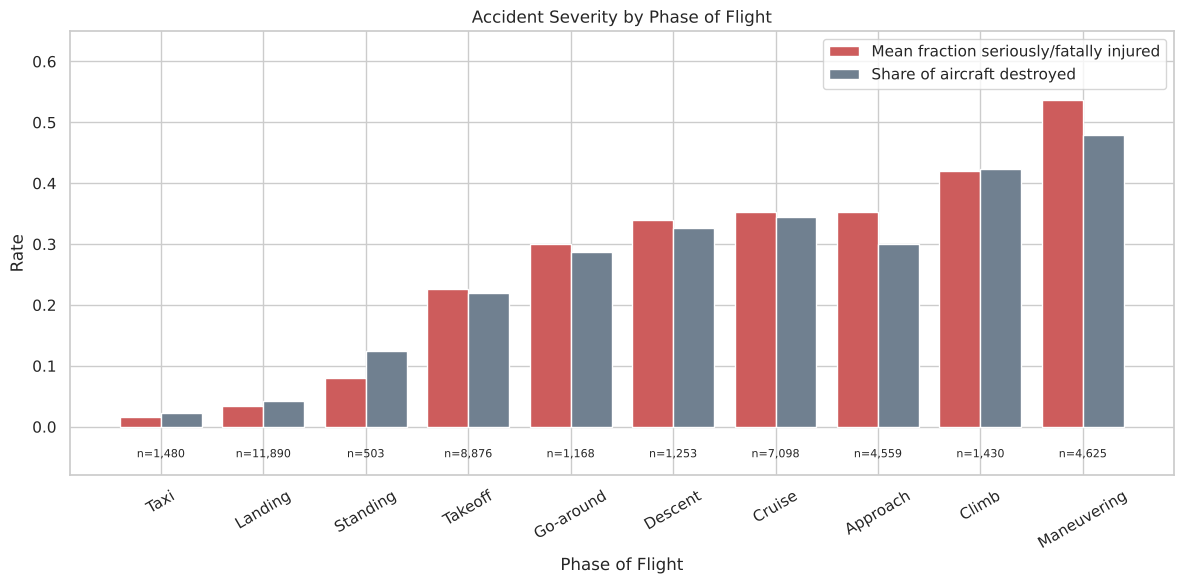

In [26]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(phase))
ax.bar(x - 0.2, phase['mean_frac_serious_fatal'], width=0.4, label='Mean fraction seriously/fatally injured', color='indianred')
ax.bar(x + 0.2, phase['destroyed_rate'], width=0.4, label='Share of aircraft destroyed', color='slategray')
for xi, n in zip(x, phase['accidents']):
    ax.text(xi, -0.05, f'n={n:,}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(phase.index, rotation=30)
ax.set_ylim(-0.08, 0.65)
ax.set_title('Accident Severity by Phase of Flight')
ax.set_xlabel('Phase of Flight')
ax.set_ylabel('Rate')
ax.legend()
plt.tight_layout()
plt.savefig('images/phase_of_flight.png', dpi=120, bbox_inches='tight')
plt.show()

In [27]:
p = df.dropna(subset=['Broad.phase.of.flight'])
chi2, p_phase, _, _ = stats.chi2_contingency(pd.crosstab(p['Broad.phase.of.flight'], p['Destroyed']))
print('Chi-square test (phase of flight vs destroyed):', fmt_p(p_phase))

Chi-square test (phase of flight vs destroyed): p < 0.001


**Discussion: phase of flight**
- Accidents during **taxi** (injury fraction 0.016) and **landing** (0.035) are rarely serious. They are common (landing is the largest group, with 11,890 accidents) but usually happen at low speed close to the ground.
- **Maneuvering** (0.536 injury, 48.0% destroyed), **climb** (0.419, 42.4%), **approach**, **cruise** and **descent** (all around 0.34–0.35) are the most severe. These accidents happen at higher speed or altitude, often after loss of control.
- The difference is highly significant (p < 0.001), and every phase has over 500 accidents.
- **For the client:** operations with a lot of low-level maneuvering, such as aerial application, banner towing or aerobatics, carry much higher severity risk than normal point-to-point flying.

#### Factor 3: Number of Engines and Engine Type

In [28]:
engines = df.dropna(subset=['Number.of.Engines']).groupby(['Size', 'Number.of.Engines']).agg(
    accidents=('Destroyed', 'size'),
    mean_frac_serious_fatal=('Frac.Serious.Fatal', 'mean'),
    destroyed_rate=('Destroyed', 'mean'))
engines[engines['accidents'] >= 50].round(3)

accidents  mean_frac_serious_fatal  destroyed_rate
Size  Number.of.Engines                                                    
Large 2.0                      704                    0.074           0.081
      3.0                      185                    0.042           0.049
      4.0                      130                    0.109           0.100
Small 1.0                    48603                    0.252           0.189
      2.0                     7221                    0.352           0.318
      4.0                      134                    0.227           0.261

In [29]:
engine_type = df.dropna(subset=['Engine.Type']).groupby('Engine.Type').agg(
    accidents=('Destroyed', 'size'),
    mean_frac_serious_fatal=('Frac.Serious.Fatal', 'mean'),
    destroyed_rate=('Destroyed', 'mean'))
engine_type = engine_type[engine_type['accidents'] >= 50].sort_values('mean_frac_serious_fatal')
engine_type.round(3)

,accidents,mean_frac_serious_fatal,destroyed_rate
Engine.Type,,,
Turbo Fan,1182,0.114,0.116
Reciprocating,51762,0.259,0.203
Turbo Jet,337,0.261,0.255
Turbo Prop,2620,0.315,0.271


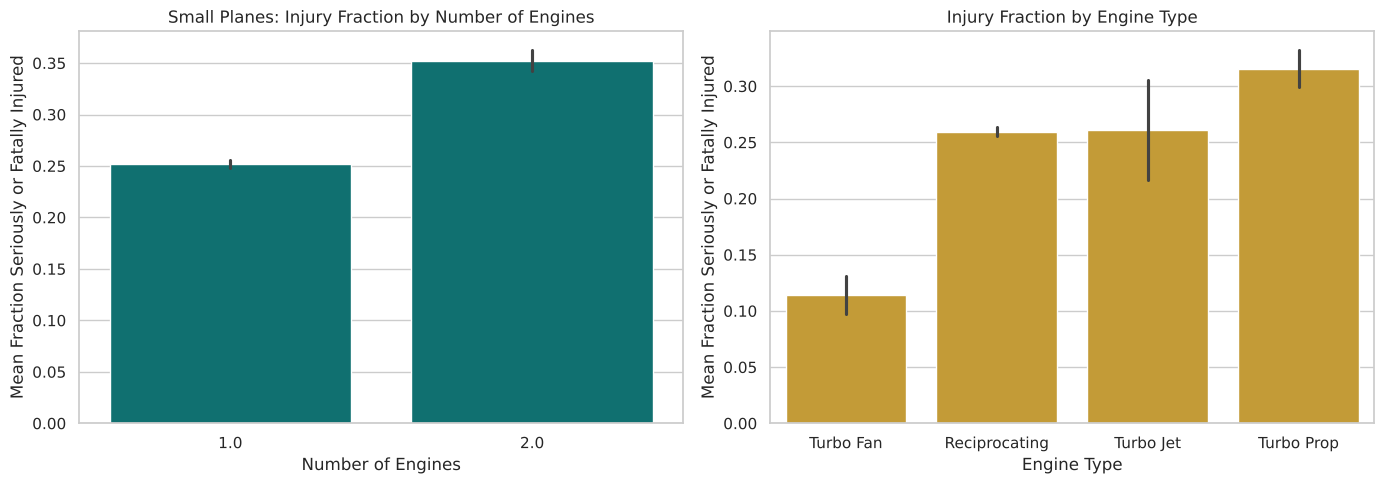

Chi-square test (1 vs 2 engines, small planes, vs destroyed): p < 0.001


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e = df.dropna(subset=['Number.of.Engines'])
e = e[e['Size'] == 'Small']
sns.barplot(data=e[e['Number.of.Engines'].isin([1, 2])], x='Number.of.Engines', y='Frac.Serious.Fatal',
            color='teal', ax=axes[0])
axes[0].set_title('Small Planes: Injury Fraction by Number of Engines')
axes[0].set_xlabel('Number of Engines')
axes[0].set_ylabel('Mean Fraction Seriously or Fatally Injured')

et = df[df['Engine.Type'].isin(engine_type.index)]
sns.barplot(data=et, x='Engine.Type', y='Frac.Serious.Fatal', order=engine_type.index, color='goldenrod', ax=axes[1])
axes[1].set_title('Injury Fraction by Engine Type')
axes[1].set_xlabel('Engine Type')
axes[1].set_ylabel('Mean Fraction Seriously or Fatally Injured')
plt.tight_layout()
plt.show()

e12 = e[e['Number.of.Engines'].isin([1, 2])]
chi2, p_eng, _, _ = stats.chi2_contingency(pd.crosstab(e12['Number.of.Engines'], e12['Destroyed']))
print('Chi-square test (1 vs 2 engines, small planes, vs destroyed):', fmt_p(p_eng))

In [31]:
# Twin-engine small planes fly in IMC more often, which helps explain their higher severity
e12.groupby('Number.of.Engines')['Weather.Condition'].value_counts(normalize=True).unstack().round(3)

Weather.Condition,IMC,VMC
Number.of.Engines,,
1.0,0.063,0.937
2.0,0.200,0.800


**Discussion: engines**
- **Engine type:** **turbofan** aircraft (mostly jet airliners) have the lowest injury fraction (0.114) and destruction rate (11.6%). **Turboprop** aircraft have the highest (0.315 injury, 27.1% destroyed), followed by **reciprocating** (piston) engines.
- **Number of engines (small planes):** surprisingly, **twin-engine** small planes had *more* severe accidents than single-engine ones, and the difference is significant (p < 0.001). Two engines do not make a small plane safer in an accident.
- This is likely **confounding**, not the engines themselves: **20.0%** of twin-engine small-plane accidents happened in instrument conditions (IMC), against **6.3%** for single-engine planes (see the table above). Twins also fly faster and are used more for business travel, all of which raise severity.
- **For the client:** don't assume twin-engine small planes are lower risk. Turbofan aircraft show the best outcomes.

## Summary of Recommendations

**Small airplanes** (20 or fewer on board)
- **Manufacturers:** **Maule**, **Aviat** and **Diamond**: all below average on both injury fraction and destruction rate, with solid sample sizes. Cessna is a reliable, slightly-better-than-average benchmark.
- **Plane types:** **Maule MX-7-235**, **Maule M-4**, **Piper PA-18-160 Super Cub**, **Cessna 180A** and **Diamond DA42**.

**Large airplanes** (more than 20 on board)
- **Manufacturers:** **Boeing** (the most data), **Bombardier** and **Embraer**.
- **Plane types:** **Boeing 777**, **Boeing 757** variants, **Bombardier CRJ (CL-600)** variants, **Embraer EMB-145LR** and **Airbus A320-232**.

**Factors that affect accident severity**
1. **Weather:** accidents in instrument conditions (IMC) are three to four times more severe than in visual conditions.
2. **Phase of flight:** maneuvering and climb are the most dangerous phases; taxi and landing are the least.
3. **Engines:** turbofan aircraft have the best outcomes; twin-engine small planes are not safer than single-engine ones.

**Limitations:** the data only contains accidents, not total flights or flight hours, so these rates describe how severe an accident is likely to be, *not* how likely an accident is. Some plane types have only 10–25 accidents, so their estimates are less certain than the manufacturer-level results.